# Self-gravity: Jeans waves against the linear dispersion relation

A small adiabatic perturbation of a uniform self-gravitating gas obeys
omega² = c² k² - 4 pi G rho0 = c² k² (1 - n_J²), with n_J = lambda / lambda_J (Jeans 1902). For
n_J < 1 it oscillates (a sound wave slowed by gravity), for n_J > 1 it grows as exp(sigma t),
sigma² = c² k² (n_J² - 1). G is set from n_J.

The setup is that of `tests/test_gravity_jeans_wave.py` (as the Athena++ jeans tests): periodic
1 x 1/2 x 1/2 box, wave vector 2 pi (1, 2, 2) (oblique to every axis), rho0 = 1, c = 1,
gamma = 5/3, amplitude 1e-6, exact cell averages; stable modes start as a standing wave at rest,
unstable ones as the growing eigenmode. HLLC, minmod, FP64, periodic multigrid Poisson solve.

1. Dispersion: omega or sigma measured from the mode amplitude over one period or e-fold, for six
   n_J, at 32 x 16 x 16 and 64 x 32 x 32 (about 10 and 21 cells per wavelength along the wave
   vector), against the analytic curve.
2. The error of the density field after one period (n_J = 0.5) and one e-fold (n_J = 1.5) at
   32 and 64 cells along x, next to the test's measured values (the test adds 128 and two more
   schemes).

Runtime: about 2 minutes on four CPU cores (an A100 node's CPU cores via SLURM, JAX on the CPU), including JAX start-up and compilation, which dominate.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # this notebook is sized for a CPU; unset it to use a GPU

import contextlib, io, time
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from luna import Config, launch


def run(cfg, **state):
    """launch(cfg, **state), as `python main.py` runs it (state: U0= or ic=, an initial state of our own),
    with its log kept out of the notebook; (RunResult, wall s)."""
    t0 = time.time()
    with contextlib.redirect_stdout(io.StringIO()):
        res = launch(cfg, **state)
    return res, time.time() - t0


# FP64, PLM, HLLC, quiet: the settings of LUNA's accuracy tests
QUIET = dict(enable_x64=True, ORDER=1, LIMITER=0, riemann_solver="hllc", PLOT_AFTER_SIM=False,
             output_cadence=10**6, diag_interval=10**6, enable_checkpointing=False, clear_output_dir=True)
BASE = replace(Config(), **QUIET)

**A custom initial state through the run path.** LUNA's registered problems (`test_problem`) fix
their initial states. A state of our own goes to `launch(cfg, U0=U)`: `U` holds the conserved
variables on the whole grid in the run's own dimension, `(3, Nx)` in 1D (rho, rho vx, E),
`(4, Nx, Ny)` in 2D, `(5, Nx, Ny, Nz)` in 3D, energy last; a shape that does not fit the config is
refused. It takes the path `python main.py` takes (`luna/ic_generation/user_ic.py`), sharded like a
registered problem; `test_problem` then only names the run.

In [2]:
import glob
from luna.file_io.read_snapshot import read_snapshot

GAM, AMP, RHO0, P0 = 5.0 / 3.0, 1e-6, 1.0, 1.0 / (5.0 / 3.0)       # c = 1
BOX = (1.0, 0.5, 0.5)
KVEC = 2 * np.pi * np.array([1.0, 2.0, 2.0])
K = float(np.linalg.norm(KVEC))


def omega2(nj):
    return K * K * (1.0 - nj * nj)


def initial(n, nj):
    """Exact cell averages: standing wave at rest (stable) or the growing eigenmode (unstable)."""
    shape = (n, n // 2, n // 2)
    h = [b / s for b, s in zip(BOX, shape)]
    X = np.meshgrid(*[(np.arange(s) + 0.5) * hh for s, hh in zip(shape, h)], indexing="ij")
    avg = np.prod([np.sinc(k * hh / (2 * np.pi)) for k, hh in zip(KVEC, h)])
    th = sum(k * x for k, x in zip(KVEC, X))
    s, c = avg * np.sin(th), avg * np.cos(th)
    rho, p = RHO0 * (1 + AMP * s), P0 * (1 + GAM * AMP * s)
    v = np.zeros((3,) + shape)
    if omega2(nj) < 0:
        v = np.sqrt(-omega2(nj)) / K * AMP * c * (KVEC / K)[:, None, None, None]
    return np.stack([rho, *(RHO0 * v), p / (GAM - 1) + 0.5 * RHO0 * (v * v).sum(0)])


def jeans(n, nj, t_end, n_snaps=16):
    """(snapshot times, mode amplitude over its initial value, U0, U at t_end)."""
    lam = 2 * np.pi / K
    cfg = replace(BASE, test_problem="Jeans-Wave", SPATIAL_DIMENSION=3, Nx=n, Ny=n // 2, Nz=n // 2,
                  Lx=BOX[0], Ly=BOX[1], Lz=BOX[2], BOUNDARY=0, gamma=GAM, SELF_GRAVITY=True,
                  GRAVITATIONAL_G=float(np.pi * nj * nj / (RHO0 * lam * lam)),   # 4 pi G rho0 = c² k² nj²
                  gravity_energy="kick", gravity_precision="double", gravity_proper_mixed=False,
                  gravity_warm_tol=0.0, gravity_warm_vcycles=8,
                  t_end=t_end, time_bet_snaps=t_end / n_snaps, output_dir="snapshots/nb09/run")
    U0 = initial(n, nj)
    res, wall = run(cfg, U0=U0)
    d0 = U0[0] - RHO0
    snaps = [read_snapshot(d) for d in sorted(glob.glob(f"{cfg.output_dir}/snapdir_*"))]
    t = np.array([s["t"] for s in snaps])
    A = np.array([np.sum((s["rho"] - RHO0) * d0) / np.sum(d0 * d0) for s in snaps])
    return t, A, U0, np.asarray(res.extra["U"], np.float64), wall

In [3]:
NJ = (0.25, 0.5, 0.75, 1.25, 1.5, 2.0)
meas = {32: {}, 64: {}}
for n in meas:
    for nj in NJ:
        w2 = omega2(nj)
        if w2 > 0:                               # one period; omega from the first zero of cos(omega t)
            t, A, U0, U, wall = jeans(n, nj, 2 * np.pi / np.sqrt(w2), 32)
            i = int(np.argmax(A < 0))
            t0 = t[i - 1] + A[i - 1] / (A[i - 1] - A[i]) * (t[i] - t[i - 1])
            meas[n][nj] = (np.pi / (2 * t0)) ** 2 / K ** 2
        else:                                    # one e-fold; sigma from the slope of ln A
            t, A, U0, U, wall = jeans(n, nj, 1 / np.sqrt(-w2))
            meas[n][nj] = -np.polyfit(t, np.log(A), 1)[0] ** 2 / K ** 2
        print(f"N={n}, n_J = {nj:4.2f}: omega²/(c²k²) measured {meas[n][nj]:+.4f}, exact {1 - nj * nj:+.4f}"
              f"   ({wall:.1f} s)")

N=32, n_J = 0.25: omega²/(c²k²) measured +0.9563, exact +0.9375   (7.4 s)


N=32, n_J = 0.50: omega²/(c²k²) measured +0.7694, exact +0.7500   (6.1 s)


N=32, n_J = 0.75: omega²/(c²k²) measured +0.4576, exact +0.4375   (6.4 s)


N=32, n_J = 1.25: omega²/(c²k²) measured -0.5015, exact -0.5625   (4.2 s)


N=32, n_J = 1.50: omega²/(c²k²) measured -1.1609, exact -1.2500   (4.2 s)


N=32, n_J = 2.00: omega²/(c²k²) measured -2.8649, exact -3.0000   (4.2 s)


... (2 outputs left out)

N=64, n_J = 0.75: omega²/(c²k²) measured +0.4425, exact +0.4375   (10.5 s)


N=64, n_J = 1.25: omega²/(c²k²) measured -0.5476, exact -0.5625   (5.6 s)


N=64, n_J = 1.50: omega²/(c²k²) measured -1.2276, exact -1.2500   (5.1 s)


N=64, n_J = 2.00: omega²/(c²k²) measured -2.9649, exact -3.0000   (5.0 s)


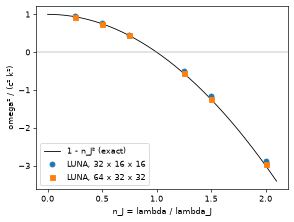

In [4]:
x = np.linspace(0, 2.1, 200)
fig, a = plt.subplots(figsize=(5, 3.8), dpi=60)
a.plot(x, 1 - x * x, "k-", lw=1, label="1 - n_J² (exact)")
for n, mk in ((32, "o"), (64, "s")):
    a.plot(list(meas[n]), list(meas[n].values()), mk, label=f"LUNA, {n} x {n // 2} x {n // 2}")
a.axhline(0, color="gray", lw=0.5)
a.set_xlabel("n_J = lambda / lambda_J"); a.set_ylabel("omega² / (c² k²)"); a.legend()
fig.tight_layout()

Field errors: (rho - exact) / amplitude after one period (exact: the initial state) and one
e-fold (exact: e times the initial perturbation).

In [5]:
# measured by the test (HLLC-minmod): L1 0.0821, 0.0197 (n_J = 0.5) and 0.0683, 0.016 (n_J = 1.5)
for nj, growth in ((0.5, 1.0), (1.5, np.e)):
    l1 = []
    for n in (32, 64):
        w2 = omega2(nj)                          # no snapshot in between: the steps are the test's
        _, _, U0, U, _ = jeans(n, nj, 2 * np.pi / np.sqrt(w2) if w2 > 0 else 1 / np.sqrt(-w2), 1)
        l1.append(float(np.mean(np.abs(U[0] - (RHO0 + (U0[0] - RHO0) * growth))) / AMP))
    print(f"n_J = {nj}: L1 (rho - exact)/AMP = {l1[0]:.4f} (32), {l1[1]:.4f} (64), order {np.log2(l1[0] / l1[1]):.2f}")

n_J = 0.5: L1 (rho - exact)/AMP = 0.0821 (32), 0.0197 (64), order 2.06


n_J = 1.5: L1 (rho - exact)/AMP = 0.0683 (32), 0.0160 (64), order 2.09


**What this shows.** The measured omega² follows c²k²(1 - n_J²) on both sides of the Jeans length: within 0.09 c²k² at 32 cells along x (about 10 cells per wavelength along the wave vector) and within 0.035 c²k² at 64 (stable oscillations slightly fast, growth slightly slow). The field errors after one period and one e-fold are the test's values (0.0821, 0.0197; 0.0683, 0.0160), second order.

Status (docs/CLAIMS.md): *validated*, "Periodic self-gravity: Jeans waves against the exact
linear solution", `tests/test_gravity_jeans_wave.py:102`.